# Introduction to numerical algorithms
## Practice class 7 - Numerical derivative and integration


In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.special import roots_legendre


## Numerical derivation

### Task 1: Derivatives with central finite differences

If we only know the values $y_i=f(x_i)$ on an equidistant grid $x_i=a+ih$, we can estimate the derivative from Taylor expansions around $x_i$:
$$f(x+h)=f+hf'+\tfrac{h^2}{2}f''+\tfrac{h^3}{6}f^{(3)}+\dots,\qquad f(x-h)=f-hf'+\tfrac{h^2}{2}f''-\tfrac{h^3}{6}f^{(3)}+\dots$$
Subtracting the two, the even terms cancel and we get the central difference
$$f'(x_i)\approx\frac{y_{i+1}-y_{i-1}}{2h},\qquad\text{error }O(h^2).$$
Using two neighbours on each side we can also cancel the $h^3$ term, which gives a fourth order formula
$$f'(x_i)\approx\frac{y_{i-2}-8y_{i-1}+8y_{i+1}-y_{i+2}}{12h},\qquad\text{error }O(h^4).$$

Write a function `my_der_calc(f, a, b, N, order)` where

- `f` is a function that accepts arrays, `a < b` are the interval ends, `N >= 10` is the number of grid points,
- `order` is 2 or 4 and selects the formula above,
- the grid is `x = np.linspace(a, b, N)`, `y = f(x)`, `h = x[1] - x[0]`,
- the output is `[df, X]`: the derivative and the grid points `X` where it is defined.

Near the ends of the interval the formula would need points outside the grid, so these points are lost: one point at each end for order 2, two points at each end for order 4. Use array slicing instead of loops (for order 2, `y[1:]` contains the values $y_{i+1}$ and `y[:-2]` contains the values $y_{i-1}$).

### Testing

Compare with the analytic derivative (given). First $\sin x$ on a coarse grid, then a function that oscillates faster and faster and therefore needs a finer grid.


In [2]:
def my_der_calc(f, a, b, N, order=2):
    if not callable(f):
        raise TypeError("f must be callable")
    a, b, N = float(a), float(b), int(N)
    if not a < b:
        raise ValueError("a must be smaller than b")
    if N < 10:
        raise ValueError("N must be at least 10")
    if order not in (2, 4):
        raise ValueError("order must be 2 or 4")

    x = np.linspace(a, b, N)
    y = np.asarray(f(x), dtype=float)
    h = x[1] - x[0]

    if order == 2:
        df = (y[2:] - y[:-2]) / (2 * h)
        X = x[1:-1]
    else:
        df = (y[:-4] - 8 * y[1:-3] + 8 * y[3:-1] - y[4:]) / (12 * h)
        X = x[2:-2]

    return [df, X]


max error order 2: 4.153199655509976e-05
max error order 4: 2.0693622371226184e-09


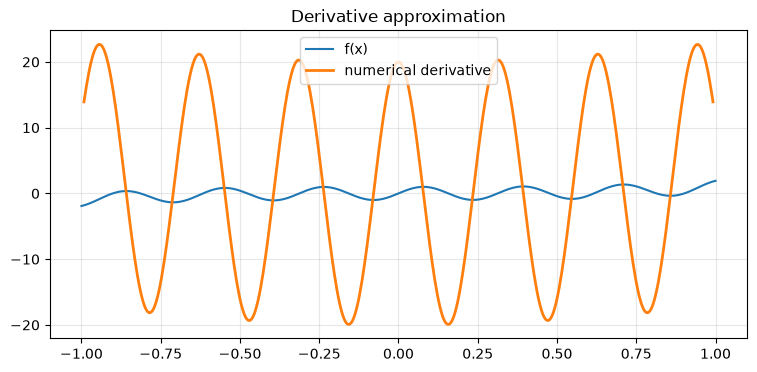

In [3]:
# Test on sin(x)
x1 = np.linspace(0, np.pi, 200)
f = np.sin
df2, X2 = my_der_calc(f, 0, np.pi, 200, order=2)
df4, X4 = my_der_calc(f, 0, np.pi, 200, order=4)
print("max error order 2:", np.max(np.abs(np.cos(X2) - df2)))
print("max error order 4:", np.max(np.abs(np.cos(X4) - df4)))

# Test on a more oscillatory function
g = lambda x: np.sin(20 * x) + x**3
xg = np.linspace(-1, 1, 500)
dg, Xg = my_der_calc(g, -1, 1, 500, order=4)
plt.figure(figsize=(9, 4))
plt.plot(xg, g(xg), label="f(x)")
plt.plot(Xg, dg, label="numerical derivative", lw=2)
plt.legend()
plt.title("Derivative approximation")
plt.grid(True, alpha=0.3)
plt.show()


## Numerical integration

### Task 2 - Newton-Cotes methods

These methods are useful for functions sampled in equidistant points or measurements with a fixed sampling frequency. 

The trapezoid rule sums up the volume of the trapezoids in each interval, or in other words it approximates the function with a line on each segment:

<img src="https://pythonnumericalmethods.studentorg.berkeley.edu/_images/21.03.1-Trapezoid_integral.png" alt="drawing" width="600"/>

The Simpson's rule approximates the function with a quadratic function for each segment and for that uses three consecutive points.

<img src="https://pythonnumericalmethods.studentorg.berkeley.edu/_images/21.04.1-Simpson_integral.png" alt="drawing" width="600"/>

1. **Implement the trapezoid rule!**
$$
\int_a^b f(x) \text{d}x = \sum_{i=0}^{n-1} h\dfrac{f(x_i)+f(x_{i+1})}{2}
$$
Write the function `my_int(f,a,b,N,method)`, where `f` is a function, `a>b` real numbers defining the integral bounds, `N` is an integer giving the number of intervals and `method` is a string giving the method to use for the calculation of the integral, in this case `method=trap`.

2. **Implement Simpson's rule!**

The integral of a segment is:
$$
\int_{x_i}^{x_{i+2}} f(x) \text{d}x = \dfrac{h}{3} \left[ f(x_i)+ 4f(x_{i+1})+  f(x_{i+2}) \right]
$$
Take a peace of paper and derive the formula for the whole interval. Implement the formula in your previous `my_int` function with `method=simp`.

$$
S_{N} = \int_{a}^{b}{f(x)}\, dx \approx \frac{h}{3} \left[ f_{0} + 4\sum_{\text{odd $i$}}^{N-1}{f(x_{i})} + 2\sum_{\text{even $i$}}^{N-2}{f(x_{i})} + f_{N} \right]
$$

3. Simpson?s rule requires an even number of intervals. What happens if `N` is odd, and why is this a limitation??????
4. Compare the performance of the two methods on 

$$
\int_0^\pi \sin(x) \text{d} x
$$ 

and 

$$
\int_{-1}^{+1} \sqrt{1-x^2} \text{d}x\;.
$$ 

Plot the results of your integral as a function of `N`, start with 100 points and go up to 3000 points with a step size of 10. Also plot the analytic result of the integral as a horizontal line. 

5. Analyze the error, defined as
$$
\text{err}(N) = \left\lvert \int_a^b f(x) \text{d}x - \text{my\_ int(f,a,b,N,method)}\right\rvert\;
$$
does it follows $\mathcal{O}(h^2)$ and $\mathcal{O}(h^4)$ for the trapezoid and the Simpson method respectively. Conduct the following experiment, compute the integral for up to $N=1000$ points and plot the error with a logaritmic y axis. Can you explein what you see??????


In [4]:
def my_int(f, a, b, N, method):
    if not callable(f):
        raise TypeError("f must be callable")
    a, b, N = float(a), float(b), int(N)
    if N <= 0:
        raise ValueError("N must be positive")
    if method == "simp":
        if N % 2 == 1:
            raise ValueError("N must be even for Simpson's rule")

    if method in ("trap", "simp"):
        h = (b - a) / N
        x = np.linspace(a, b, N + 1)
        y = np.asarray(f(x), dtype=float)

        if method == "trap":
            return h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])

        if method == "simp":
            return (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])

    if method == "quad":
        xi, wi = roots_legendre(N)
        xq = 0.5 * (b - a) * xi + 0.5 * (a + b)
        return 0.5 * (b - a) * np.sum(wi * f(xq))

    raise ValueError("method must be 'trap', 'simp', or 'quad'")


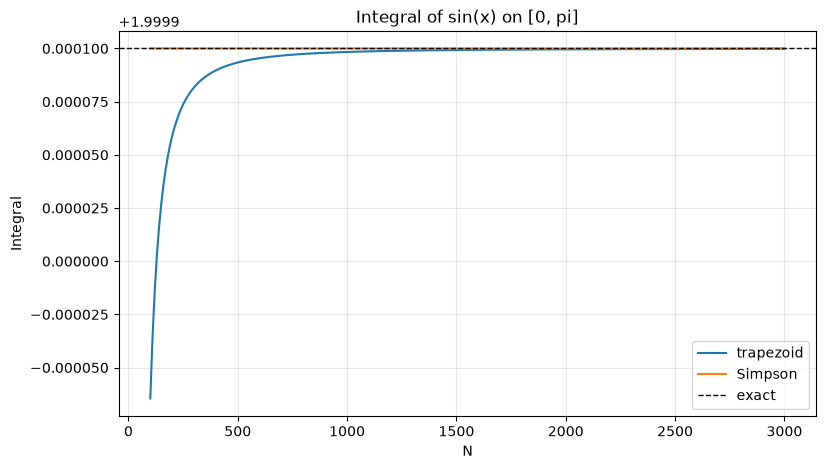

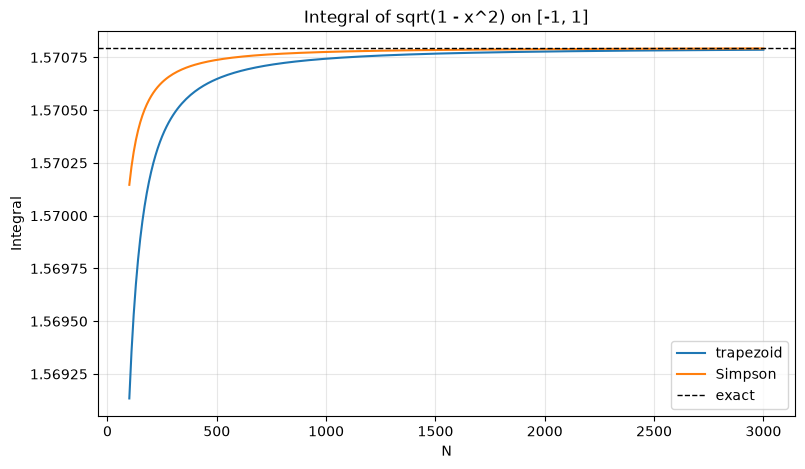

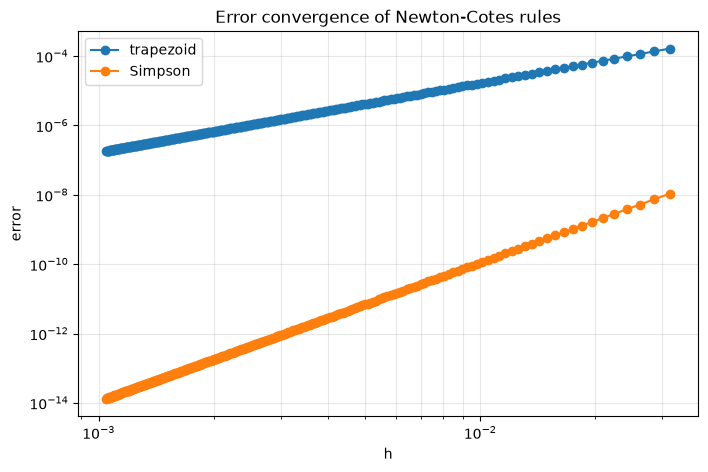

In [5]:
f1 = np.sin
f2 = lambda x: np.sqrt(np.maximum(0.0, 1 - x**2))

exact1 = 2.0
exact2 = np.pi / 2

N_values = np.arange(100, 3001, 10)
trap_vals = np.array([my_int(f1, 0.0, np.pi, N, 'trap') for N in N_values])
simp_vals = np.array([my_int(f1, 0.0, np.pi, N, 'simp') for N in N_values])

plt.figure(figsize=(9, 5))
plt.plot(N_values, trap_vals, label='trapezoid')
plt.plot(N_values, simp_vals, label='Simpson')
plt.axhline(exact1, color='black', linestyle='--', lw=1, label='exact')
plt.xlabel('N')
plt.ylabel('Integral')
plt.title('Integral of sin(x) on [0, pi]')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

trap2 = np.array([my_int(f2, -1.0, 1.0, N, 'trap') for N in N_values])
simp2 = np.array([my_int(f2, -1.0, 1.0, N, 'simp') for N in N_values])
plt.figure(figsize=(9, 5))
plt.plot(N_values, trap2, label='trapezoid')
plt.plot(N_values, simp2, label='Simpson')
plt.axhline(exact2, color='black', linestyle='--', lw=1, label='exact')
plt.xlabel('N')
plt.ylabel('Integral')
plt.title('Integral of sqrt(1 - x^2) on [-1, 1]')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

h_vals = np.pi / N_values
err_trap = np.abs(exact1 - trap_vals)
err_simp = np.abs(exact1 - simp_vals)
plt.figure(figsize=(8, 5))
plt.loglog(h_vals, err_trap, 'o-', label='trapezoid')
plt.loglog(h_vals, err_simp, 'o-', label='Simpson')
plt.xlabel('h')
plt.ylabel('error')
plt.title('Error convergence of Newton-Cotes rules')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()


### Task 3 - Gauss-Legendre quadrature
Sometimes you need very accurate integral of known functions. The Gauss-Legendre quadrature with $n$ points integrate polinomials of order $2n-1$ exactly. For that uses a special sampling of points ($x_i$) with special weights ($w_i$).

1. Use scipy to find the nodes and the weights (see the code below with the function `roots_legendre`) and then implement the Gauss-Legendre quadrature.
$$
\int_{-1}^{1} f(x) \text{d} x = \sum_{i=1}^n w_i f(x_i)
$$
Use your previous function `my_int` with `method=quad` and `N` is the number of points. 

2. To make it a widely applicable method we need to make it work with arbitrary intervals. It can be done with the change of variables.
$$
\int_a^b f(x) \text{d} x = \dfrac{b-a}{2} \sum_{i=1}^n w_i f\left( \dfrac{a+b}{2}+\dfrac{b-a}{2}x_i \right) = \sum_{i=1}^N \tilde{w}_i f(\tilde{x}_i)
$$ 
implement this in your code. Note that it gives the original formula for `a=-1` and `b=1`.

3. Analyze the performance of the method on 

$$
\int_0^\pi \sin(x) \text{d} x$$ 

and 

$$
\int_{-1}^{+1} \sqrt{1-x^2} \text{d}x\;.
$$

Plot the error of the integral as you increase the number of points from $N=4$ up to $N=20$. Also compare with your previous results with trapezoid and Simspon integrals (for that use the earlier range in $N$). 


sin integral, 4 to 20 points: [1.99998423 2.00000011 2.         2.         2.         2.
 2.         2.         2.         2.         2.         2.
 2.         2.         2.         2.         2.        ]
circle integral, 4 to 20 points: [1.58027753 1.57590633 1.57386398 1.57278196 1.57215522 1.57176712
 1.57151396 1.57134177 1.57122059 1.57113283 1.57106771 1.57101838
 1.57098032 1.57095048 1.57092677 1.57090768 1.57089215]


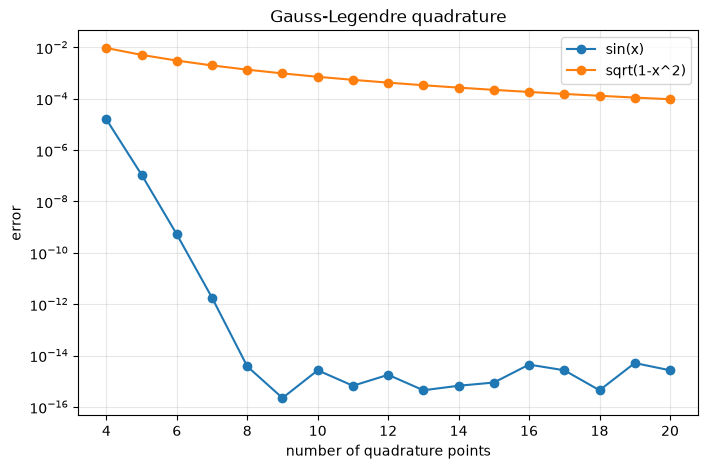

In [6]:
N_quad = np.arange(4, 21)
quad_sin = np.array([my_int(f1, 0.0, np.pi, n, 'quad') for n in N_quad])
quad_circle = np.array([my_int(f2, -1.0, 1.0, n, 'quad') for n in N_quad])

print('sin integral, 4 to 20 points:', quad_sin)
print('circle integral, 4 to 20 points:', quad_circle)

plt.figure(figsize=(8, 5))
plt.semilogy(N_quad, np.abs(exact1 - quad_sin), 'o-', label='sin(x)')
plt.semilogy(N_quad, np.abs(exact2 - quad_circle), 'o-', label='sqrt(1-x^2)')
plt.xlabel('number of quadrature points')
plt.ylabel('error')
plt.title('Gauss-Legendre quadrature')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()


### BONUS Task - The volume of an N dimensional hypersphere.

Use Monte Carlo integration to solve the problem. 

1. Generate a large number of points in the $N$ dimensional Euclidean space inside a hyper cube with side length 2 in the $[-1,1]$ interval. You can do it with the `np.uniform` function. 
2. Check that the point is inside the sphere or not.
3. The volume is:
$$
V_{\text{sphere}} = V_{\text{cube}} \dfrac{\text{Number of points inside the sphere}}{\text{Total number of points}} 
$$

The analytic solution for a $d$ dimensional unit sphere:
$$
V_d = \dfrac{\pi^{d/2}}{\Gamma(\frac{d}{2}+\frac{1}{2})} 
$$
where $\Gamma(x)$ is the [Gamma funtion](https://mathworld.wolfram.com/GammaFunction.html).

4. Check the error of your Monte Carlo integral for $d=10$. Use exponentially increasing number of points for the integral up to $N=10^6$ and plot the error with a logarithmic $x$ axis.


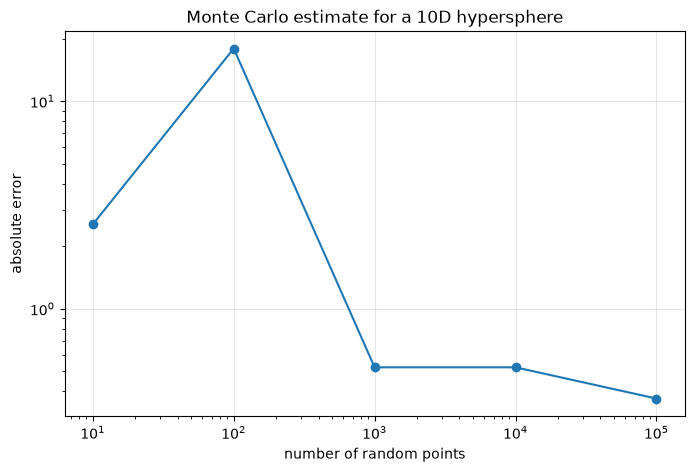

In [7]:
import math

def sphere_volume_mc(d, n_points=200000):
    points = np.random.uniform(-1.0, 1.0, size=(n_points, d))
    r2 = np.sum(points**2, axis=1)
    inside = np.count_nonzero(r2 <= 1.0)
    cube_volume = 2.0**d
    return cube_volume * inside / n_points

d = 10
n_values = np.array([10**k for k in range(1, 6)])
errors = []
for n in n_values:
    approx = sphere_volume_mc(d, n_points=int(n))
    exact = np.pi**(d / 2) / math.gamma(d / 2 + 1)
    errors.append(abs(exact - approx))

plt.figure(figsize=(8, 5))
plt.loglog(n_values, errors, 'o-')
plt.xlabel('number of random points')
plt.ylabel('absolute error')
plt.title('Monte Carlo estimate for a 10D hypersphere')
plt.grid(True, alpha=0.3)
plt.show()
